# TAM400 VPN Traffic Classification
## Final systematic Random Forest experiment

**Students:** Shucayb AHmed Said and Ayub Ali Barre. **Group:** 17.

Can stronger regularization reduce the training–validation gap while preserving useful VPN classification? This notebook contains the complete experiment, from raw-data download to the final results. Use a CPU runtime and **Runtime > Run all**. The structured search, shortlisted 10-fold comparisons and diagnostic curves can take a substantial amount of CPU time.

The saved outputs come from an actual local execution. No external results file or saved model is imported. Colab recomputes the whole experiment when all cells are run. Model choices use training-data cross-validation. Test metrics cannot change them.

This is an offline classification experiment using nine measured network-flow features, not a detector for a computer's current VPN switch.

## 1. Import the libraries
These libraries are normally available in Colab. The first cell installs a library only if it is missing.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"sklearn": "scikit-learn", "pandas": "pandas",
            "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
from io import StringIO
from urllib.request import urlretrieve
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
from sklearn.base import clone
print("matplotlib:", __import__("matplotlib").__version__)

Python: 3.12.14
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3
matplotlib: 3.10.7


## 2. Download and inspect the raw dataset
We use the ISCXVPN2016 dataset described by the **Canadian Institute for Cybersecurity at the University of New Brunswick, Canada**. It contains labelled traffic recorded with and without a VPN. The original university description and paper explain how the data was collected.

- **Original dataset source:** https://www.unb.ca/cic/datasets/vpn.html
- **Research paper:** https://doi.org/10.5220/0005740704070414
- **Exact feature-file copy used here:** https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff

Our code downloads this fixed public copy of the feature file for a 15-second flow timeout. Only the **raw data** is downloaded. The checksum checks that we have the expected copy each time. It does **not** verify that the copy is identical to the university archive. The official download route leads to a registration form. We have not independently compared our copy with that archive.

ARFF files have a header followed by comma-separated data rows. `class1` contains the original application labels.

In [2]:
url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_hash = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")
if not data_file.exists():
    urlretrieve(url, data_file)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == expected_hash, "Unexpected dataset file"

# Read the ARFF column names and then its data rows.
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[start:])), names=columns)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (18758, 24)


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4,1523088,97590.739583,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4,1517774,87383.785714,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15,1079974,89312.019231,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8,2441990,127659.871795,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10,3042717,133013.359551,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## 3. Create the inputs and target, then clean the data
We select nine numerical measurements to keep the project small. `class1` is used only to create the target; including it in the inputs would reveal the answer.

Negative durations and traffic rates are invalid, so we replace them with missing values. We first keep one copy of identical input-and-label rows. If an input vector still occurs more than once, it has conflicting labels, so we remove both versions. These cleaning rules are specific to this dataset.

In [3]:
features = ["duration", "flowPktsPerSecond", "flowBytesPerSecond",
            "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
            "mean_active", "mean_idle"]
X = df[features].copy()
y = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

negative_cells = int((X < 0).sum().sum())
X[X < 0] = np.nan
clean = pd.concat([X, y], axis=1)
clean = clean.drop_duplicates()  # Keep one row when both inputs and label are identical.
clean = clean.drop_duplicates(subset=features, keep=False)  # Remove conflicting labels.
removed_rows = len(df) - len(clean)
X, y = clean[features], clean["vpn"]

print("Invalid negative cells replaced with missing values:", negative_cells)
print("Duplicate or conflicting rows removed:", removed_rows)
print("Clean rows:", len(clean))
print("Number of input features:", X.shape[1])

Invalid negative cells replaced with missing values: 1240
Duplicate or conflicting rows removed: 779
Clean rows: 17979
Number of input features: 9


## 4. Fixed data split and selection rules
Keep the original nine inputs, cleaning rules and stratified 80/20 split with seed 42: 14,383 training rows and 3,596 test rows.

Desired ranges are roughly 92–93% full-training accuracy, 0.91–0.92 validation VPN F1 and 91–92% test accuracy. These are aspirations, not model-selection constraints or stopping rules. High training accuracy alone does not define overfitting.

**Rules fixed before fitting:**

1. Use three shuffled stratified folds (seed 42) for a structured depth/leaf search, followed by focused sampling/criterion and split/tree-count grids. No random parameter combinations are drawn.
2. Use a fixed allowance of **0.005 absolute VPN F1** when balancing validation performance against the fit gap. Carry forward the highest-scoring setting and promising lower-gap alternatives. Reuse duplicate configurations rather than fitting them twice in the broad search.
3. Shortlist 18 regularized candidates. Add the original and previous forests as fixed controls, then evaluate all 20 on the same ten shuffled stratified folds (seed 42).
4. Find the highest mean ten-fold validation F1. Among candidates within 0.005 of it, choose the smallest nonnegative mean fold-training minus validation F1 gap, then lower fold-training accuracy, lower validation standard deviation and deterministic complexity order. This is a practical trade-off, not a statistical equivalence test. The allowance will not be widened after seeing results.
5. Refit/freeze the selected configuration using all training rows. Learning and validation curves are diagnostics on training data only and cannot change that choice. Evaluate the frozen models in one final test phase, once per unique configuration, then reuse predictions for every metric and chart.

Full-training accuracy/F1 and mean fold-training accuracy/F1 are both reported. Selection uses paired fold-training and validation scores from the same fitted forests. A full-training-minus-CV gap is separately labelled. Never subtract accuracy from F1.

This test partition was viewed in earlier revisions. Keeping it out of this search does not turn it into a new independent holdout. The ten-fold score also participates in selection, so it is a selection estimate, not unbiased external confirmation.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training flows:", len(X_train))
print("Test flows:", len(X_test))
print("Training class counts (0 = NonVPN, 1 = VPN):")
print(y_train.value_counts().sort_index())

Training flows: 14383
Test flows: 3596
Training class counts (0 = NonVPN, 1 = VPN):
vpn
0    6927
1    7456
Name: count, dtype: int64


## 5. Explore the training data
Duration means the elapsed time between the first and last packet in a flow. **ISCXFlowMeter stores duration in microseconds.** Its original implementation documents the unit and divides duration by 1,000,000 when calculating packets per second:
https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172

For the histogram, divide by **1,000,000 to show seconds**. The full-range plot keeps the long flows. The second panel zooms to 0–15 seconds for readability and states how many flows are outside that view. It does not remove them from training. The file's 15-second timeout name is not a guarantee that every recorded duration is at most 15 seconds.

Many flows end quickly, while fewer last much longer. This produces a right-skewed distribution. The plots describe the observed distribution, not the applications responsible for it.

The Pearson table measures **linear** association with VPN=1. Low correlation does not mean that a feature is useless. Random Forest can learn nonlinear relationships and interactions between features. Keep all nine inputs. Only the graph uses seconds; the model inputs remain in their original units.

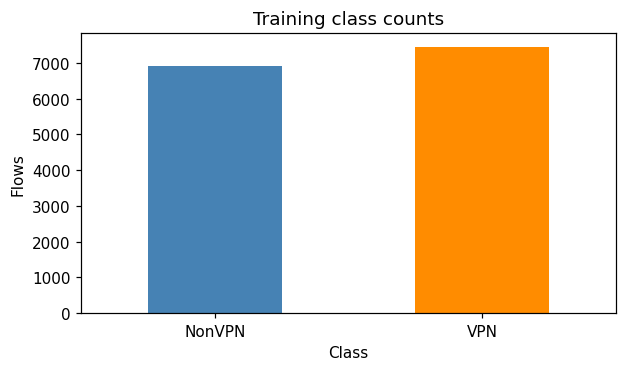

Training duration in seconds:


count    14383.000
mean        10.178
std         14.860
min          0.000
25%          0.692
50%         11.850
75%         14.960
95%         14.999
max        601.405
Name: duration, dtype: float64

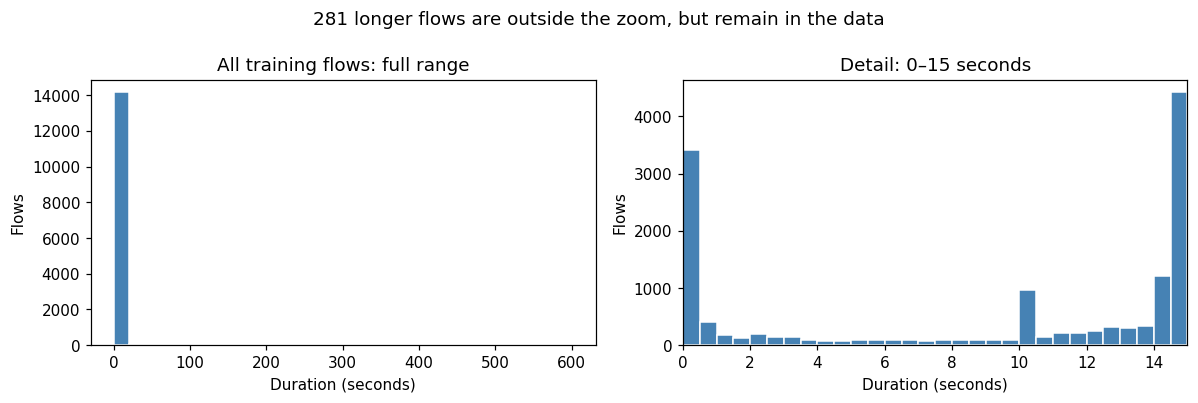

,Feature,Pearson correlation with VPN
0,mean_flowiat,0.0532
1,min_flowiat,0.0378
2,std_flowiat,0.0050
3,flowPktsPerSecond,0.0007
4,mean_active,-0.0077
5,max_flowiat,-0.0133
6,mean_idle,-0.0151
7,flowBytesPerSecond,-0.0347
8,duration,-0.0670


In [5]:
fig, ax = plt.subplots(figsize=(5.8, 3.5), num="class_counts")
y_train.value_counts().sort_index().plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set(xticklabels=["NonVPN", "VPN"], xlabel="Class", ylabel="Flows", title="Training class counts")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

duration_seconds = X_train["duration"].dropna() / 1_000_000
duration_summary = duration_seconds.describe(percentiles=[0.25, 0.50, 0.75, 0.95])
print("Training duration in seconds:")
display(duration_summary.round(3))
outside_zoom = int((duration_seconds > 15).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), num="duration_histogram")
axes[0].hist(duration_seconds, bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="All training flows: full range", xlabel="Duration (seconds)", ylabel="Flows")
axes[1].hist(duration_seconds, bins=np.linspace(0, 15, 31), color="steelblue", edgecolor="white")
axes[1].set(title="Detail: 0–15 seconds", xlabel="Duration (seconds)", ylabel="Flows", xlim=(0, 15))
fig.suptitle(f"{outside_zoom:,} longer flows are outside the zoom, but remain in the data")
plt.tight_layout()
plt.show()

training_data = X_train.copy()
training_data["vpn"] = y_train
correlation_table = training_data.corr(numeric_only=True)["vpn"].drop("vpn").sort_values(ascending=False)
display(correlation_table.rename_axis("Feature").reset_index(name="Pearson correlation with VPN").round(4))

## 6. Train the baseline
We use `DummyClassifier` as our reference model. We call it the **baseline**. Our `strategy="most_frequent"` setting makes it predict the most common training class for every flow. This lets us check whether the other models improve on a simple prediction rule.

Every pipeline fits its median imputer on training data only. Keeping preprocessing inside the pipeline also protects the validation folds.

In [6]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)
print("Baseline trained on", len(X_train), "flows.")

Baseline trained on 14383 flows.


## 7. Train SGDClassifier
`SGDClassifier` learns a linear decision boundary. We add `StandardScaler` because the numerical inputs have very different ranges. The scaler is fitted inside the pipeline.

In [7]:
sgd_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SGDClassifier(random_state=42))
])
sgd_model.fit(X_train, y_train)
print("SGDClassifier trained on", len(X_train), "flows.")

SGDClassifier trained on 14383 flows.


## 8. Fit the two fixed Random Forest controls
The original forest uses 100 trees and default complexity settings. The previous tuned forest uses 200 trees, depth 16, leaf minimum 2, split minimum 2, six features per split, a 0.75 bootstrap draw and Gini splitting.

These two settings remain fixed. They provide reference points when stronger regularization is tested. Each pipeline fits its median imputer on training data only. Random Forest does not require scaling.

In [8]:
original_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])
original_model.fit(X_train, y_train)
forest_model = original_model
previous_model = clone(original_model).set_params(
    model__n_estimators=200, model__max_depth=16,
    model__min_samples_leaf=2, model__min_samples_split=2,
    model__max_features=6, model__max_samples=0.75, model__criterion="gini")
previous_model.fit(X_train, y_train)
print("Both fixed controls fitted on training rows only.")

Both fixed controls fitted on training rows only.


## 9. Check full-training accuracy and F1
These predictions use data the fitted models have already seen. Report both accuracy and VPN F1. A high training score alone is not enough to diagnose overfitting. Next, compare training-fold F1 with validation-fold F1, using the same metric.

In [9]:
pipelines = {"Baseline": baseline, "SGDClassifier": sgd_model, "Original RF": original_model, "Previous Tuned RF": previous_model}
training_rows = []
for name, model in pipelines.items():
    prediction = model.predict(X_train)
    training_rows.append({"Model": name,
                          "Training accuracy": accuracy_score(y_train, prediction),
                          "Training VPN F1": f1_score(y_train, prediction, zero_division=0)})
training_results = pd.DataFrame(training_rows)
display(training_results.round(4))

,Model,Training accuracy,Training VPN F1
0,Baseline,0.5184,0.6828
1,SGDClassifier,0.5893,0.6420
2,Original RF,0.9999,0.9999
3,Previous Tuned RF,0.9673,0.9688


## 10. Initial three-fold comparisons
Use three shuffled stratified folds for the broad phase. Imputation is fitted separately inside every fold. VPN F1 is the primary score; training and validation accuracy are recorded separately. The initial DummyClassifier and SGD results remain visible for context.

The final forest comparison later uses ten folds for all three forests. Its values must not be mixed with these three-fold screening scores.

,Model,CV training F1,CV training accuracy,CV F1 mean,CV F1 std,CV accuracy
2,Original RF,1.0000,1.0000,0.8946,0.0062,0.8898
3,Previous Tuned RF,0.9728,0.9716,0.8916,0.0017,0.8855
0,Baseline,0.6828,0.5184,0.6828,0.0000,0.5184
1,SGDClassifier,0.6030,0.5948,0.6003,0.0710,0.5922


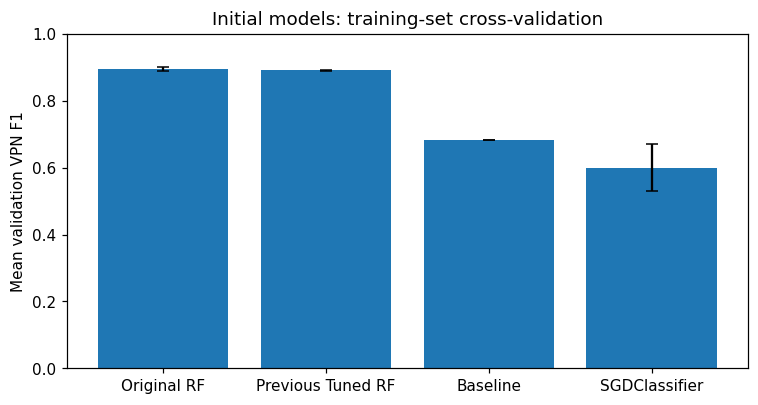

In [10]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {"f1": "f1", "accuracy": "accuracy"}
cv_scores = {}
comparison_rows = []
for name, model in pipelines.items():
    scores = cross_validate(model, X_train, y_train, scoring=scoring, cv=cv,
                            return_train_score=True, n_jobs=2)
    cv_scores[name] = scores
    comparison_rows.append({
        "Model": name,
        "CV training F1": scores["train_f1"].mean(),
        "CV training accuracy": scores["train_accuracy"].mean(),
        "CV F1 mean": scores["test_f1"].mean(),
        "CV F1 std": scores["test_f1"].std(),
        "CV accuracy": scores["test_accuracy"].mean()})
comparison = pd.DataFrame(comparison_rows).sort_values("CV F1 mean", ascending=False)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(7, 3.8), num="initial_comparison")
ax.bar(comparison["Model"], comparison["CV F1 mean"], yerr=comparison["CV F1 std"], capsize=4)
ax.set(ylim=(0, 1), ylabel="Mean validation VPN F1", title="Initial models: training-set cross-validation")
plt.tight_layout()
plt.show()

## Systematic search A: control depth and leaf size
We first compare all 81 depth–leaf pairs below with the other settings fixed. Three shuffled stratified folds and VPN F1 provide an efficient, consistent first comparison. The imputer is fitted inside each fold's pipeline.

The fixed near-best allowance is **0.005 absolute F1**. We carry the highest validation-F1 setting and then near-best settings with smaller paired training–validation F1 gaps. Training accuracy is a tie-breaker, not a target filter. Fold SD describes variation; the allowance is a practical trade-off, not a confidence interval. The complete staged strategy was specified before fitting.

Each exact parameter dictionary is evaluated once. This bounded search does not claim to explore every possible forest.

In [11]:
from itertools import product
import json
from datetime import datetime, timezone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

SELECTION_MARGIN = 0.005
F1_MARGIN = SELECTION_MARGIN
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = {"f1": "f1", "accuracy": "accuracy"}
parameter_names = ["max_depth", "min_samples_leaf", "min_samples_split",
                   "max_features", "max_samples", "criterion", "n_estimators"]
all_candidates = pd.DataFrame()
seen_parameters = set()

def parameter_key(params):
    return json.dumps(params, sort_keys=True)

def complexity_key(params):
    # This fixed ordering is used only after the score and gap tie-breakers.
    depth = params["model__max_depth"]
    features = params["model__max_features"]
    if features == "sqrt":
        features = int(np.sqrt(X_train.shape[1]))
    elif isinstance(features, float):
        features = max(1, int(features * X_train.shape[1]))
    samples = params["model__max_samples"]
    return (1000000 if depth is None else depth,
            -params["model__min_samples_leaf"], -params["model__min_samples_split"],
            features, 1.0 if samples is None else samples,
            params["model__n_estimators"], params["model__criterion"] != "gini")

def balanced_order(table, prefix):
    return table.sort_values(
        [prefix + " selection gap", prefix + " training accuracy",
         prefix + " F1 std", "complexity", "id"], kind="stable")

def promising_settings(table, count):
    # Always carry the peak-F1 setting, then gap-ranked near-best settings.
    by_f1 = table.sort_values(["CV3 F1", "CV3 F1 std", "id"],
                             ascending=[False, True, True], kind="stable")
    near_best = table.loc[table["CV3 F1"] >= by_f1.iloc[0]["CV3 F1"] - F1_MARGIN]
    ordered = pd.concat([by_f1.head(1), balanced_order(near_best, "CV3"), by_f1])
    return ordered.drop_duplicates("id").head(count).copy()

def evaluate_stage(proposals, stage):
    global all_candidates
    fresh, batch_keys = [], set()
    for params in proposals:
        key = parameter_key(params)
        if key not in seen_parameters and key not in batch_keys:
            fresh.append(params)
            batch_keys.add(key)
    print(stage + ":", len(fresh), "new configurations;", len(proposals) - len(fresh), "exact repeats skipped")
    if not fresh:
        return
    grid = [{key: [value] for key, value in params.items()} for params in fresh]
    search = GridSearchCV(clone(forest_model).set_params(model__n_jobs=1), grid,
                          scoring=scoring, refit=False, cv=cv3,
                          return_train_score=True, n_jobs=2, error_score="raise")
    search.fit(X_train, y_train)
    records = []
    for index, params in enumerate(search.cv_results_["params"]):
        result = search.cv_results_
        row = {"id": "RF-" + str(len(all_candidates) + index + 1).zfill(3),
               "stage": stage, "params": params, "complexity": complexity_key(params),
               "CV3 training accuracy": float(result["mean_train_accuracy"][index]),
               "CV3 training F1": float(result["mean_train_f1"][index]),
               "CV3 training F1 std": float(result["std_train_f1"][index]),
               "CV3 F1": float(result["mean_test_f1"][index]),
               "CV3 F1 std": float(result["std_test_f1"][index]),
               "CV3 accuracy": float(result["mean_test_accuracy"][index]),
               "CV3 validation fold F1": [float(result[f"split{fold}_test_f1"][index]) for fold in range(3)],
               "CV3 training fold F1": [float(result[f"split{fold}_train_f1"][index]) for fold in range(3)]}
        row["candidate_id"] = row["id"]
        row.update({name: params["model__" + name] for name in parameter_names})
        row["CV3 gap"] = row["CV3 training F1"] - row["CV3 F1"]
        row["CV3 selection gap"] = max(0.0, row["CV3 gap"])
        records.append(row)
    all_candidates = pd.concat([all_candidates, pd.DataFrame(records)], ignore_index=True)
    seen_parameters.update(batch_keys)
    print("Total unique three-fold configurations:", len(all_candidates))
    display(promising_settings(all_candidates, 4)[
        ["id", "stage"] + parameter_names + ["CV3 training accuracy", "CV3 training F1", "CV3 F1", "CV3 F1 std", "CV3 gap"]].round(4))

depth_values = [4, 5, 6, 7, 8, 9, 10, 12, 14]
leaf_values = [4, 6, 8, 10, 12, 16, 20, 25, 30]
fixed = {"model__min_samples_split": 20, "model__max_features": 3,
         "model__max_samples": 0.60, "model__criterion": "gini", "model__n_estimators": 200}
stage_a = [{**fixed, "model__max_depth": depth, "model__min_samples_leaf": leaf}
           for depth, leaf in product(depth_values, leaf_values)]
evaluate_stage(stage_a, "A: depth and leaf")

A: depth and leaf: 81 new configurations; 0 exact repeats skipped
Total unique three-fold configurations: 81


,id,stage,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples,criterion,n_estimators,CV3 training accuracy,CV3 training F1,CV3 F1,CV3 F1 std,CV3 gap
72,RF-073,A: depth and leaf,14,4,20,3,0.6,gini,200,0.9157,0.9200,0.8794,0.0003,0.0407
74,RF-075,A: depth and leaf,14,8,20,3,0.6,gini,200,0.9065,0.9114,0.8746,0.0016,0.0369
63,RF-064,A: depth and leaf,12,4,20,3,0.6,gini,200,0.9071,0.9123,0.8745,0.0029,0.0377
73,RF-074,A: depth and leaf,14,6,20,3,0.6,gini,200,0.9114,0.9160,0.8766,0.0020,0.0395


## Systematic search B: change sampling and the split criterion
Carry four distinct promising depth–leaf pairs from stage A. Cross four feature counts, four bootstrap fractions and two split criteria around these pairs: 128 proposals before removing repeats.

With nine predictors, `max_features="sqrt"` selects three predictors per split, so testing both `3` and `"sqrt"` would duplicate that choice. Bootstrap fractions change how many training draws each tree uses; they do not change the training partition.

In [12]:
stage_b_seeds = promising_settings(all_candidates, 4)
assert len(stage_b_seeds[["max_depth", "min_samples_leaf"]].drop_duplicates()) == 4
stage_b = []
for params in stage_b_seeds["params"]:
    for features, samples, criterion in product([2, 3, 4, 5], [0.40, 0.50, 0.60, 0.70], ["gini", "entropy"]):
        stage_b.append({**params, "model__max_features": features,
                        "model__max_samples": samples, "model__criterion": criterion})
evaluate_stage(stage_b, "B: sampling and criterion")

B: sampling and criterion: 124 new configurations; 4 exact repeats skipped
Total unique three-fold configurations: 205


,id,stage,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples,criterion,n_estimators,CV3 training accuracy,CV3 training F1,CV3 F1,CV3 F1 std,CV3 gap
111,RF-112,B: sampling and criterion,14,4,20,5,0.7,entropy,200,0.9237,0.9275,0.8829,0.0003,0.0447
140,RF-141,B: sampling and criterion,14,8,20,5,0.6,entropy,200,0.9110,0.9156,0.8796,0.0018,0.0359
171,RF-172,B: sampling and criterion,12,4,20,5,0.6,entropy,200,0.9095,0.9144,0.8779,0.0019,0.0365
132,RF-133,B: sampling and criterion,14,8,20,4,0.6,entropy,200,0.9109,0.9155,0.8782,0.0012,0.0374


## Systematic search C: change split size and forest size
Carry four promising full settings from stages A and B. Cross all seven planned minimum split sizes and three tree counts around them: 84 proposals before removing repeats.

The complete strategy makes at most 293 unique proposals. Exact repeats reuse their previous three-fold result. All stages use the same folds and scoring. This is a structured, limited search rather than an exhaustive search of every interaction.

In [13]:
stage_c_seeds = promising_settings(all_candidates, 4)
stage_c = []
for params in stage_c_seeds["params"]:
    for split, trees in product([10, 20, 30, 40, 50, 75, 100], [200, 300, 500]):
        stage_c.append({**params, "model__min_samples_split": split, "model__n_estimators": trees})
evaluate_stage(stage_c, "C: split and trees")
assert len(all_candidates) <= 293
assert all_candidates["params"].map(parameter_key).nunique() == len(all_candidates)
print("Final broad-search count:", len(all_candidates))
print("This count excludes the two historical controls and diagnostic curve fits.")

C: split and trees: 80 new configurations; 4 exact repeats skipped
Total unique three-fold configurations: 285


,id,stage,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples,criterion,n_estimators,CV3 training accuracy,CV3 training F1,CV3 F1,CV3 F1 std,CV3 gap
207,RF-208,C: split and trees,14,4,10,5,0.7,entropy,500,0.9383,0.9413,0.8867,0.0012,0.0546
108,RF-109,B: sampling and criterion,14,4,20,5,0.6,gini,200,0.9175,0.9216,0.8826,0.0014,0.0389
203,RF-204,B: sampling and criterion,14,6,20,5,0.7,gini,200,0.9171,0.9213,0.8818,0.0016,0.0395
204,RF-205,B: sampling and criterion,14,6,20,5,0.7,entropy,200,0.9190,0.9230,0.8818,0.0009,0.0412


Final broad-search count: 285
This count excludes the two historical controls and diagnostic curve fits.


## Shortlist 18 candidates and measure full-training performance
Carry the highest three-fold validation-F1 candidate, then near-best candidates ordered by gap. Fill any remaining shortlist places with the strongest remaining validation-F1 candidates. The same fixed 0.005 allowance applies.

Fit each shortlisted setting on all available training rows to report training accuracy and VPN F1. These are different from mean fold-training scores: each CV fit sees fewer rows. The primary selection gap uses training and validation F1 from the same fold fits. The desired 92–93% range is descriptive and never makes a weak model eligible.

In [14]:
shortlist_table = promising_settings(all_candidates, 18).reset_index(drop=True)
assert len(shortlist_table) == 18
for index, row in shortlist_table.iterrows():
    candidate = clone(forest_model).set_params(**row["params"])
    candidate.fit(X_train, y_train)
    training_prediction = candidate.predict(X_train)
    shortlist_table.loc[index, "Training accuracy"] = accuracy_score(y_train, training_prediction)
    shortlist_table.loc[index, "Training VPN F1"] = f1_score(y_train, training_prediction)
    del candidate
shortlist_table["Full-training minus CV3 F1"] = shortlist_table["Training VPN F1"] - shortlist_table["CV3 F1"]
display(shortlist_table[["id"] + parameter_names + ["Training accuracy", "Training VPN F1",
        "CV3 training F1", "CV3 F1", "CV3 F1 std", "CV3 gap", "Full-training minus CV3 F1"]].round(4))
print("The main CV gap uses paired fold-training scores; the last column uses the full-training refit.")

,id,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples,criterion,n_estimators,Training accuracy,Training VPN F1,CV3 training F1,CV3 F1,CV3 F1 std,CV3 gap,Full-training minus CV3 F1
0,RF-208,14,4,10,5,0.7,entropy,500,0.9376,0.9406,0.9413,0.8867,0.0012,0.0546,0.0539
1,RF-109,14,4,20,5,0.6,gini,200,0.9196,0.9235,0.9216,0.8826,0.0014,0.0389,0.0409
2,RF-204,14,6,20,5,0.7,gini,200,0.9199,0.9239,0.9213,0.8818,0.0016,0.0395,0.0421
3,RF-205,14,6,20,5,0.7,entropy,200,0.9217,0.9255,0.9230,0.8818,0.0009,0.0412,0.0437
4,RF-248,12,4,10,5,0.6,entropy,500,0.9193,0.9236,0.9264,0.8822,0.0005,0.0442,0.0414
5,RF-210,14,4,20,5,0.7,entropy,500,0.9257,0.9292,0.9278,0.8832,0.0007,0.0446,0.0460
6,RF-209,14,4,20,5,0.7,entropy,300,0.9249,0.9284,0.9278,0.8832,0.0009,0.0447,0.0453
7,RF-112,14,4,20,5,0.7,entropy,200,0.9241,0.9276,0.9275,0.8829,0.0003,0.0447,0.0447
8,RF-206,14,4,10,5,0.7,entropy,200,0.9376,0.9406,0.9409,0.8864,0.0009,0.0545,0.0542
9,RF-207,14,4,10,5,0.7,entropy,300,0.9372,0.9403,0.9413,0.8866,0.0007,0.0547,0.0537


The main CV gap uses paired fold-training scores; the last column uses the full-training refit.


## Final validation: 18 candidates and two controls on the same ten folds
Evaluate the shortlist, original forest and previous tuned forest on identical ten-fold splits. Ten folds fit each model on 90% of the available training partition per fold, giving a further comparison closer to the final refit size. This is more expensive than three folds, so we limit it to 20 models.

The ten-fold results are used for model selection. They are not an independent unbiased performance estimate: the data have already informed the search. Fold standard deviation describes variation, not a confidence interval.

In [15]:
control_models = {"Original RF": original_model, "Previous Tuned RF": previous_model}
final_candidates = shortlist_table.to_dict("records")
fitted_control_models = {}
for name, control_model in control_models.items():
    params = {"model__" + key: control_model.get_params()["model__" + key] for key in parameter_names}
    fitted_control = clone(control_model).fit(X_train, y_train)
    fitted_control_models[name] = fitted_control
    training_prediction = fitted_control.predict(X_train)
    final_candidates.append({"id": name, "candidate_id": name, "params": params, "stage": "Historical control",
                             "complexity": complexity_key(params),
                             "Training accuracy": accuracy_score(y_train, training_prediction),
                             "Training VPN F1": f1_score(y_train, training_prediction)})

cv10_records = []
for row in final_candidates:
    print("Ten-fold validation:", row["id"])
    candidate = clone(forest_model).set_params(**row["params"]).set_params(model__n_jobs=1)
    scores = cross_validate(candidate, X_train, y_train, scoring=scoring, cv=cv10,
                            return_train_score=True, n_jobs=2, error_score="raise")
    result = dict(row)
    result.update({"CV10 training accuracy": float(scores["train_accuracy"].mean()),
                   "CV10 training F1": float(scores["train_f1"].mean()),
                   "CV10 training F1 std": float(scores["train_f1"].std()),
                   "CV10 F1": float(scores["test_f1"].mean()),
                   "CV10 F1 std": float(scores["test_f1"].std()),
                   "CV10 accuracy": float(scores["test_accuracy"].mean()),
                   "CV10 validation fold F1": scores["test_f1"].tolist(),
                   "CV10 training fold F1": scores["train_f1"].tolist(),
                   "CV folds": 10})
    result.update({name: row["params"]["model__" + name] for name in parameter_names})
    result["CV10 gap"] = result["CV10 training F1"] - result["CV10 F1"]
    result["CV10 selection gap"] = max(0.0, result["CV10 gap"])
    result["Full-training minus CV10 F1"] = result["Training VPN F1"] - result["CV10 F1"]
    cv10_records.append(result)
cv10_table = pd.DataFrame(cv10_records)
assert len(cv10_table) == 20
display(cv10_table[["id", "Training accuracy", "Training VPN F1", "CV10 training accuracy",
                   "CV10 training F1", "CV10 F1", "CV10 F1 std", "CV10 gap",
                   "Full-training minus CV10 F1"]].round(4))

Ten-fold validation: RF-208
Ten-fold validation: RF-109
Ten-fold validation: RF-204
Ten-fold validation: RF-205
Ten-fold validation: RF-248
Ten-fold validation: RF-210
Ten-fold validation: RF-209
Ten-fold validation: RF-112
Ten-fold validation: RF-206
Ten-fold validation: RF-207
Ten-fold validation: RF-096
Ten-fold validation: RF-111
Ten-fold validation: RF-110
Ten-fold validation: RF-104
Ten-fold validation: RF-246
Ten-fold validation: RF-247
Ten-fold validation: RF-197
Ten-fold validation: RF-103
Ten-fold validation: Original RF
Ten-fold validation: Previous Tuned RF


,id,Training accuracy,Training VPN F1,CV10 training accuracy,CV10 training F1,CV10 F1,CV10 F1 std,CV10 gap,Full-training minus CV10 F1
0,RF-208,0.9376,0.9406,0.9378,0.9407,0.8933,0.0086,0.0474,0.0472
1,RF-109,0.9196,0.9235,0.9189,0.9229,0.8879,0.0097,0.0350,0.0356
2,RF-204,0.9199,0.9239,0.9193,0.9234,0.8868,0.0098,0.0366,0.0371
3,RF-205,0.9217,0.9255,0.9206,0.9246,0.8892,0.0083,0.0354,0.0364
4,RF-248,0.9193,0.9236,0.9202,0.9245,0.8871,0.0090,0.0374,0.0365
5,RF-210,0.9257,0.9292,0.9245,0.9282,0.8904,0.0075,0.0378,0.0388
6,RF-209,0.9249,0.9284,0.9247,0.9284,0.8893,0.0076,0.0392,0.0392
7,RF-112,0.9241,0.9276,0.9250,0.9287,0.8895,0.0076,0.0391,0.0381
8,RF-206,0.9376,0.9406,0.9375,0.9405,0.8938,0.0087,0.0467,0.0468
9,RF-207,0.9372,0.9403,0.9376,0.9406,0.8933,0.0077,0.0473,0.0470


## Freeze the final model using validation evidence
Find the best mean ten-fold VPN F1 across all 20 models. Retain candidates within **0.005 absolute F1**, then prefer the smallest nonnegative paired training–validation F1 gap. Tie-breakers are lower fold-training accuracy, lower validation SD and the prespecified complexity order.

The tolerance keeps validation performance near the best available result and prevents selecting a weak model merely for low training accuracy. It is not widened to reach the desired ranges. If a historical control is the justified compromise, it can remain the final model.

Refit and freeze the selected model now. Subsequent learning and validation curves are diagnostics and cannot alter this choice. The previously viewed held-out partition remains a limitation of the project.

In [16]:
peak_row = cv10_table.sort_values(["CV10 F1", "CV10 F1 std", "id"],
                                  ascending=[False, True, True], kind="stable").iloc[0]
final_threshold = float(peak_row["CV10 F1"] - F1_MARGIN)
eligible_final = cv10_table.loc[cv10_table["CV10 F1"] >= final_threshold].copy()
selected = balanced_order(eligible_final, "CV10").iloc[0]
selected_id = str(selected["id"])
selected_params = dict(selected["params"])
final_model = clone(forest_model).set_params(**selected_params)
final_model.fit(X_train, y_train)
models = {"Original RF": fitted_control_models["Original RF"],
          "Previous Tuned RF": fitted_control_models["Previous Tuned RF"],
          "Final RF": final_model}
comparison_rows = []
for name, source_id in [("Original RF", "Original RF"), ("Previous Tuned RF", "Previous Tuned RF"), ("Final RF", selected_id)]:
    source_row = cv10_table.loc[cv10_table["id"] == source_id].iloc[0]
    comparison_rows.append({"Model": name,
        "Training accuracy": float(source_row["Training accuracy"]),
        "Training VPN F1": float(source_row["Training VPN F1"]),
        "CV training F1": float(source_row["CV10 training F1"]),
        "CV training accuracy": float(source_row["CV10 training accuracy"]),
        "CV F1 mean": float(source_row["CV10 F1"]),
        "CV F1 std": float(source_row["CV10 F1 std"]),
        "CV accuracy": float(source_row["CV10 accuracy"]), "CV folds": 10,
        "CV F1 gap": float(source_row["CV10 gap"]),
        "Full-training-CV F1 gap": float(source_row["Full-training minus CV10 F1"])})
training_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(training_comparison.round(4))
final_training_prediction = final_model.predict(X_train)
final_selection = {
    "frozen_utc": datetime.now(timezone.utc).isoformat(),
    "rule": "within 0.005 of best ten-fold F1; minimum nonnegative paired-fold F1 gap; lower fold-training accuracy; lower SD; lower complexity",
    "margin": F1_MARGIN, "threshold": final_threshold,
    "peak_id": str(peak_row["id"]), "peak_cv10_f1": float(peak_row["CV10 F1"]),
    "eligible_count": len(eligible_final), "eligible_ids": eligible_final["id"].tolist(),
    "broad_configurations": len(all_candidates), "shortlisted_models": len(shortlist_table),
    "models_evaluated_cv10": len(cv10_table), "selected_id": selected_id,
    "selected_params": selected_params,
    "training_accuracy": float(accuracy_score(y_train, final_training_prediction)),
    "training_f1": float(f1_score(y_train, final_training_prediction)),
    "cv10_training_accuracy": float(selected["CV10 training accuracy"]),
    "cv10_training_f1": float(selected["CV10 training F1"]),
    "cv10_f1": float(selected["CV10 F1"]), "cv10_f1_std": float(selected["CV10 F1 std"]),
    "paired_fold_f1_gap": float(selected["CV10 gap"]),
    "full_training_minus_cv10_f1": float(selected["Full-training minus CV10 F1"])}
print("FROZEN FINAL MODEL:", selected_id)
print(json.dumps(final_selection, indent=2))
print("The target ranges do not trigger more tuning or a different selection.")

,Training accuracy,Training VPN F1,CV training F1,CV training accuracy,CV F1 mean,CV F1 std,CV accuracy,CV folds,CV F1 gap,Full-training-CV F1 gap
Model,,,,,,,,,,
Original RF,0.9999,0.9999,1.0000,1.0000,0.9016,0.0072,0.8972,10,0.0984,0.0983
Previous Tuned RF,0.9673,0.9688,0.9699,0.9684,0.8965,0.0090,0.8908,10,0.0733,0.0723
Final RF,0.9999,0.9999,1.0000,1.0000,0.9016,0.0072,0.8972,10,0.0984,0.0983


FROZEN FINAL MODEL: Original RF
{
  "frozen_utc": "2026-10-17T08:46:16.047127+00:00",
  "rule": "within 0.005 of best ten-fold F1; minimum nonnegative paired-fold F1 gap; lower fold-training accuracy; lower SD; lower complexity",
  "margin": 0.005,
  "threshold": 0.8966073691142055,
  "peak_id": "Original RF",
  "peak_cv10_f1": 0.9016073691142055,
  "eligible_count": 1,
  "eligible_ids": [
    "Original RF"
  ],
  "broad_configurations": 285,
  "shortlisted_models": 18,
  "models_evaluated_cv10": 20,
  "selected_id": "Original RF",
  "selected_params": {
    "model__max_depth": null,
    "model__min_samples_leaf": 1,
    "model__min_samples_split": 2,
    "model__max_features": "sqrt",
    "model__max_samples": null,
    "model__criterion": "gini",
    "model__n_estimators": 100
  },
  "training_accuracy": 0.9999304734756309,
  "training_f1": 0.9999329354168064,
  "cv10_training_accuracy": 1.0,
  "cv10_training_f1": 1.0,
  "cv10_f1": 0.9016073691142055,
  "cv10_f1_std": 0.0071944820673

## Learning curves after model selection
For the original, previous and final forests, plot training and held-out VPN F1 against increasing training sample count. Use the same three stratified folds and sample-size fractions for each model, with `shuffle=True` and seed 42. This is a training-data diagnostic, not another parameter search.

The largest point uses about two-thirds of the available training partition because the third fold is held out. Bands show one fold standard deviation, not confidence intervals. A narrower gap is useful only if validation performance remains strong. The frozen choice does not change after inspecting these curves.

In this saved run, Final RF is Original RF, so those two learning curves intentionally coincide. This is evidence that the final choice did not improve the original fit gap.


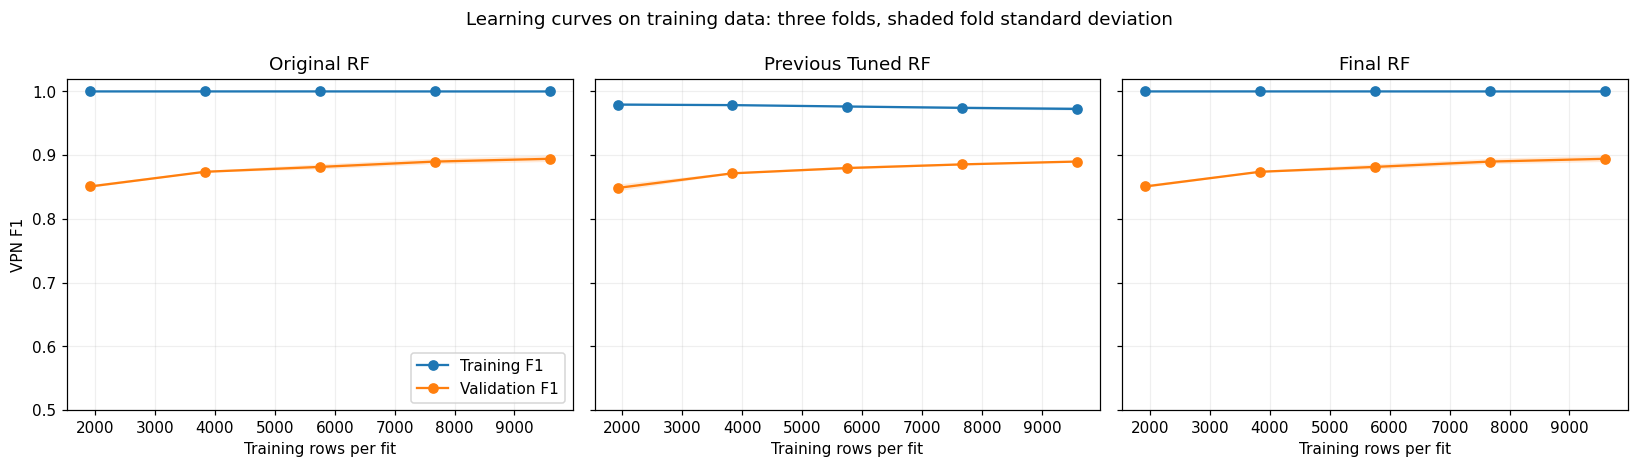

,Model,Training rows per fit,Training F1,Training F1 std,Validation F1,Validation F1 std,F1 gap
0,Original RF,1917,1.0000,0.0000,0.8509,0.0022,0.1491
1,Original RF,3835,1.0000,0.0000,0.8739,0.0012,0.1261
2,Original RF,5752,1.0000,0.0000,0.8816,0.0040,0.1184
3,Original RF,7670,1.0000,0.0001,0.8900,0.0043,0.1100
4,Original RF,9588,0.9999,0.0000,0.8943,0.0051,0.1056
5,Previous Tuned RF,1917,0.9793,0.0020,0.8486,0.0053,0.1308
6,Previous Tuned RF,3835,0.9785,0.0002,0.8715,0.0012,0.1070
7,Previous Tuned RF,5752,0.9763,0.0013,0.8798,0.0021,0.0965
8,Previous Tuned RF,7670,0.9742,0.0021,0.8855,0.0015,0.0887
9,Previous Tuned RF,9588,0.9726,0.0027,0.8900,0.0011,0.0825


In [17]:
learning_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True, num="learning_curves")
for ax, (name, model) in zip(axes, models.items()):
    sizes, train_f1, validation_f1 = learning_curve(
        clone(model), X_train, y_train, cv=cv3, scoring="f1",
        train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=42, n_jobs=2)
    train_mean, validation_mean = train_f1.mean(axis=1), validation_f1.mean(axis=1)
    train_std, validation_std = train_f1.std(axis=1), validation_f1.std(axis=1)
    for i, size in enumerate(sizes):
        learning_rows.append({"Model":name, "Training rows per fit":int(size),
            "Training F1":train_mean[i], "Training F1 std":train_std[i],
            "Validation F1":validation_mean[i], "Validation F1 std":validation_std[i],
            "F1 gap":train_mean[i]-validation_mean[i]})
    ax.plot(sizes, train_mean, "o-", label="Training F1")
    ax.plot(sizes, validation_mean, "o-", label="Validation F1")
    ax.fill_between(sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
    ax.fill_between(sizes, validation_mean-validation_std, validation_mean+validation_std, alpha=0.15)
    ax.set(title=name, xlabel="Training rows per fit", ylim=(0.5, 1.02))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("VPN F1")
axes[0].legend(loc="lower right")
fig.suptitle("Learning curves on training data: three folds, shaded fold standard deviation")
plt.tight_layout()
plt.show()
learning_curve_table = pd.DataFrame(learning_rows)
display(learning_curve_table.round(4))

## Validation curves for depth and leaf size
Vary one parameter at a time while holding every other parameter at its frozen final value. These diagnostics use three-fold CV on training rows. They help describe excessive complexity and underfitting, but cannot select a new model after the ten-fold decision.

The depth values include the chosen value even if a fixed control wins. The leaf curve includes both flexible and strongly regularized settings. Compare training F1 with validation F1, and consider fold variation.

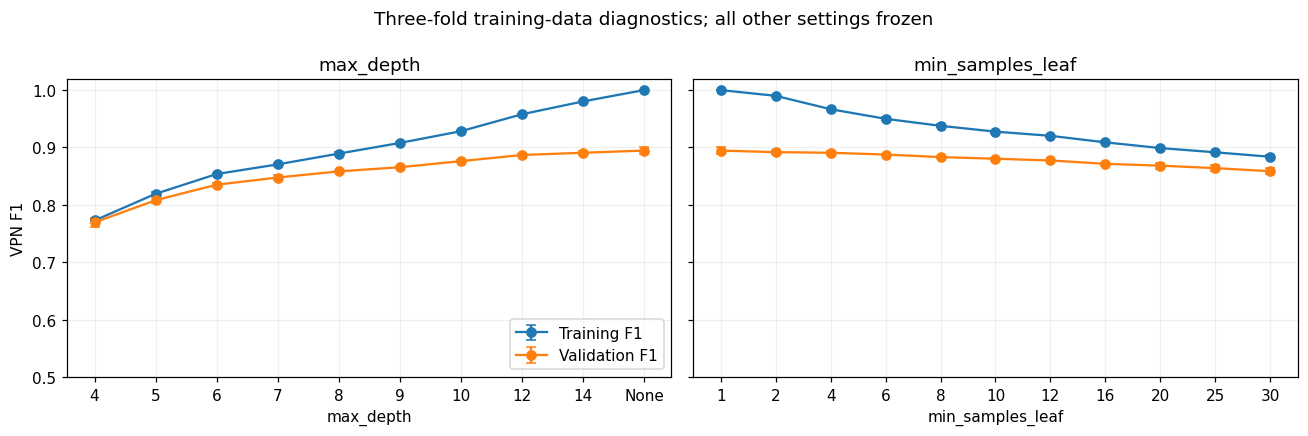

,Parameter,Value,Training F1,Training F1 std,Validation F1,Validation F1 std
0,max_depth,4.0,0.7727,0.0005,0.7694,0.0075
1,max_depth,5.0,0.8192,0.0031,0.8080,0.0052
2,max_depth,6.0,0.8537,0.0024,0.8351,0.0035
3,max_depth,7.0,0.8706,0.0020,0.8476,0.0050
4,max_depth,8.0,0.8893,0.0031,0.8583,0.0007
5,max_depth,9.0,0.9079,0.0014,0.8656,0.0015
6,max_depth,10.0,0.9283,0.0017,0.8762,0.0012
7,max_depth,12.0,0.9578,0.0011,0.8869,0.0017
8,max_depth,14.0,0.9802,0.0014,0.8908,0.0033
9,max_depth,NaN,1.0000,0.0000,0.8946,0.0062


In [18]:
validation_rows = []
depth_values = [4, 5, 6, 7, 8, 9, 10, 12, 14]
chosen_depth = final_model.named_steps["model"].max_depth
if chosen_depth not in depth_values:
    depth_values.append(chosen_depth)
depth_values = sorted([v for v in depth_values if v is not None]) + ([None] if None in depth_values else [])
curve_specs = [("max_depth", depth_values), ("min_samples_leaf", [1, 2, 4, 6, 8, 10, 12, 16, 20, 25, 30])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, num="validation_curves")
for ax, (parameter, values) in zip(axes, curve_specs):
    diagnostic = GridSearchCV(clone(final_model), {"model__"+parameter:values},
        scoring="f1", refit=False, cv=cv3, return_train_score=True, n_jobs=2, error_score="raise")
    diagnostic.fit(X_train, y_train)
    frame = pd.DataFrame(diagnostic.cv_results_)
    labels = ["None" if value is None else str(value) for value in values]
    x = np.arange(len(values))
    ax.errorbar(x, frame["mean_train_score"], yerr=frame["std_train_score"], marker="o", capsize=3, label="Training F1")
    ax.errorbar(x, frame["mean_test_score"], yerr=frame["std_test_score"], marker="o", capsize=3, label="Validation F1")
    ax.set(xticks=x, xticklabels=labels, xlabel=parameter, title=parameter, ylim=(0.5,1.02))
    ax.grid(alpha=0.2)
    for i, value in enumerate(values):
        validation_rows.append({"Parameter":parameter,"Value":value,
            "Training F1":frame.loc[i,"mean_train_score"],"Training F1 std":frame.loc[i,"std_train_score"],
            "Validation F1":frame.loc[i,"mean_test_score"],"Validation F1 std":frame.loc[i,"std_test_score"]})
axes[0].set_ylabel("VPN F1")
axes[0].legend(loc="lower right")
fig.suptitle("Three-fold training-data diagnostics; all other settings frozen")
plt.tight_layout()
plt.show()
validation_curve_table = pd.DataFrame(validation_rows)
display(validation_curve_table.round(4))

## One final test evaluation after freezing
The final parameters are frozen. Evaluate the three fixed forests in this one phase and reuse their stored predictions. If the final choice equals a control, reuse that control's predictions rather than predicting again. No candidate table or selection rule receives test metrics.

The three model columns use the same ten-fold validation procedure, the same training partition and the same development-test partition. VPN=1 is the positive class. This phase cannot justify another tuning pass or changing the chosen model.

In [19]:
test_rows = []
test_predictions = {}
test_probabilities = {}
prediction_cache = {}
for name, model in models.items():
    cache_key = repr(sorted(model.named_steps["model"].get_params().items()))
    if cache_key not in prediction_cache:
        probabilities = model.predict_proba(X_test)[:, 1]
        # Standard binary RF decision: choose class 1 only above 0.5;
        # ties choose class 0, matching sklearn's default argmax rule.
        prediction_cache[cache_key] = (probabilities, (probabilities > 0.5).astype(int))
    scores, prediction = prediction_cache[cache_key]
    test_predictions[name] = prediction
    test_probabilities[name] = scores
    test_rows.append({"Model":name, "Test accuracy":accuracy_score(y_test,prediction),
        "VPN precision":precision_score(y_test,prediction), "VPN recall":recall_score(y_test,prediction),
        "VPN F1":f1_score(y_test,prediction), "ROC-AUC":roc_auc_score(y_test,scores)})
test_results = pd.DataFrame(test_rows).set_index("Model")
final_comparison = training_comparison.join(test_results)
final_comparison["Training-test accuracy gap"] = final_comparison["Training accuracy"]-final_comparison["Test accuracy"]
display(final_comparison.T.round(4))
print("Unique frozen forests evaluated:",len(prediction_cache))
print("Model choice remains:",selected_id)

Model,Original RF,Previous Tuned RF,Final RF
Training accuracy,0.9999,0.9673,0.9999
Training VPN F1,0.9999,0.9688,0.9999
CV training F1,1.0000,0.9699,1.0000
CV training accuracy,1.0000,0.9684,1.0000
CV F1 mean,0.9016,0.8965,0.9016
CV F1 std,0.0072,0.0090,0.0072
CV accuracy,0.8972,0.8908,0.8972
CV folds,10.0000,10.0000,10.0000
CV F1 gap,0.0984,0.0733,0.0984
Full-training-CV F1 gap,0.0983,0.0723,0.0983


Unique frozen forests evaluated: 2
Model choice remains: Original RF


## Confusion matrices and example predictions
Rows show the actual class and columns show the predicted class. NonVPN predicted as VPN is a false alarm. VPN predicted as NonVPN is a missed VPN flow. Every figure below reuses the final test predictions.

Original RF false alarms: 189 misses: 147
Previous Tuned RF false alarms: 214 misses: 137
Final RF false alarms: 189 misses: 147


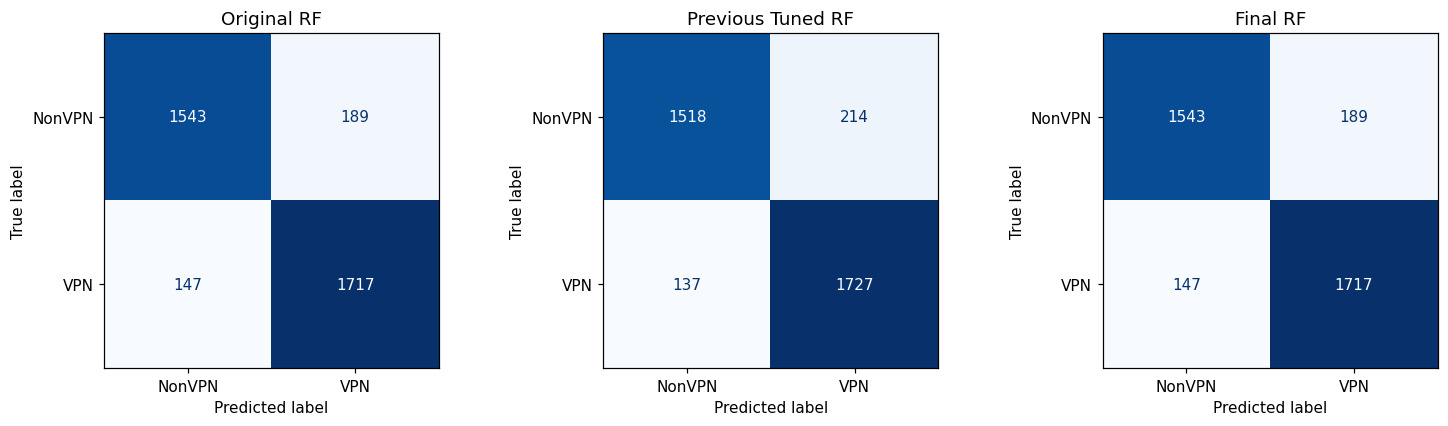

,Source row,Actual,Final prediction
0,15291,1,0
1,4257,0,1
2,1260,0,0
3,2990,0,0
4,18400,0,0
5,8769,1,1
6,8271,1,1
7,9953,1,1
8,5218,0,0
9,886,0,1


In [20]:
confusion_matrices = {}
fig, axes = plt.subplots(1,3,figsize=(13.8,4),num="confusion_matrices")
for ax,name in zip(axes,models):
    matrix=confusion_matrix(y_test,test_predictions[name],labels=[0,1])
    confusion_matrices[name]=matrix
    ConfusionMatrixDisplay(matrix,display_labels=["NonVPN","VPN"]).plot(ax=ax,cmap="Blues",colorbar=False)
    ax.set_title(name)
    print(name,"false alarms:",matrix[0,1],"misses:",matrix[1,0])
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Source row":X_test.index,"Actual":y_test.to_numpy(),
    "Final prediction":test_predictions["Final RF"]}).head(10))

## Final comparison and target check
The figures and tables describe observed outcomes. The selected model can miss every desired range. Neither target checking nor test results cause another search.

Compare the original, previous and final models using their shared ten-fold scores. Distinguish the paired fold-training/validation gap used in selection from full-training F1 minus mean CV F1. Learning curves use three folds and provide a separate diagnostic.

Model,Original RF,Previous Tuned RF,Final RF
Training accuracy,0.9999,0.9673,0.9999
Training VPN F1,0.9999,0.9688,0.9999
CV training F1,1.0000,0.9699,1.0000
CV training accuracy,1.0000,0.9684,1.0000
CV F1 mean,0.9016,0.8965,0.9016
CV F1 std,0.0072,0.0090,0.0072
CV accuracy,0.8972,0.8908,0.8972
CV folds,10.0000,10.0000,10.0000
CV F1 gap,0.0984,0.0733,0.0984
Full-training-CV F1 gap,0.0983,0.0723,0.0983


,Metric,Desired,Measured,Within range
0,Training accuracy,92–93%,0.999930,False
1,10-fold validation VPN F1,0.91–0.92,0.901607,False
2,Test accuracy,91–92%,0.906563,False


Final candidate: Original RF
Final hyperparameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__max_features': 'sqrt', 'model__max_samples': None, 'model__criterion': 'gini', 'model__n_estimators': 100}
CV allowance: 0.005
No test-based model selection or target-driven follow-up search was performed.


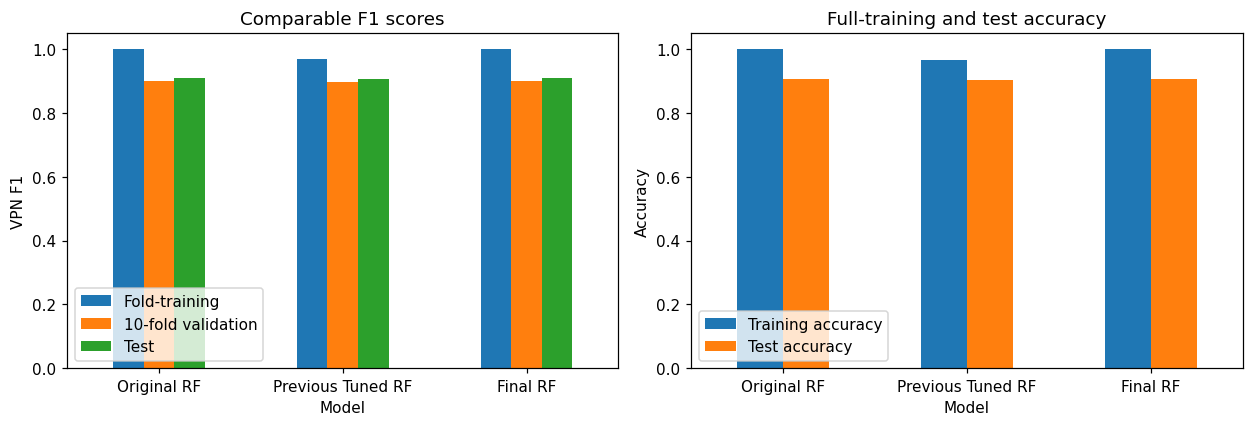

In [21]:
final = final_comparison.loc["Final RF"]
display(final_comparison.T.round(4))
target_check = pd.DataFrame([
    {"Metric":"Training accuracy","Desired":"92–93%","Measured":final["Training accuracy"],"Within range":0.92<=final["Training accuracy"]<=0.93},
    {"Metric":"10-fold validation VPN F1","Desired":"0.91–0.92","Measured":final["CV F1 mean"],"Within range":0.91<=final["CV F1 mean"]<=0.92},
    {"Metric":"Test accuracy","Desired":"91–92%","Measured":final["Test accuracy"],"Within range":0.91<=final["Test accuracy"]<=0.92}])
display(target_check)
print("Final candidate:",selected_id)
print("Final hyperparameters:",selected_params)
print("CV allowance:",SELECTION_MARGIN)
print("No test-based model selection or target-driven follow-up search was performed.")
fig,axes=plt.subplots(1,2,figsize=(11.5,4),num="final_comparison")
final_comparison[["CV training F1","CV F1 mean","VPN F1"]].plot.bar(ax=axes[0],rot=0)
axes[0].set(ylabel="VPN F1",ylim=(0,1.05),title="Comparable F1 scores")
axes[0].legend(["Fold-training","10-fold validation","Test"],loc="lower left")
final_comparison[["Training accuracy","Test accuracy"]].plot.bar(ax=axes[1],rot=0)
axes[1].set(ylabel="Accuracy",ylim=(0,1.05),title="Full-training and test accuracy")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

## Interpretation and limitations

### Observed result from the saved run

The fixed rule retains models within **0.005 absolute F1** of the best ten-fold mean, then prefers the smallest nonnegative paired fold-training minus validation F1 gap. Further tie-breakers are lower fold-training accuracy, lower validation standard deviation and a fixed complexity order. The desired ranges do not filter candidates.

The best mean is **0.901607**, giving a cutoff of **0.896607**. Only Original RF is eligible, so **Final RF is Original RF**. Previous Tuned RF scores **0.896546**, just **0.00006093** below that cutoff. This is a sensitive practical rule, not evidence of statistically significant superiority. We did not widen the allowance after observing results.

The strongest new regularized candidate, **RF-206**, has **93.76%** training accuracy, **0.8938** ten-fold F1 and a **0.0467** paired gap. Its validation loss versus the peak is **0.0078**, exceeding the fixed allowance. RF-210 reaches **92.57%** training accuracy, but its ten-fold F1 is **0.8904**. Neither candidate was evaluated on the test set.

The final model therefore does **not** reduce overfitting: its paired F1 gap is **0.0984**, unchanged from Original RF and larger than the previous model's **0.0733**. The search found a real trade-off, but did not achieve the requested improvement under the prespecified rule. No evaluated ten-fold candidate reached 0.91 validation F1.

The Original and Final learning curves coincide. At the largest three-fold learning-curve size, mean training F1 is 0.9999 and validation F1 is 0.8943, leaving a gap of 0.1056. The previous forest has a smaller 0.0825 gap at that size. Validation improves as more training rows are used, but the remaining separation supports the concern about overfitting.

The depth diagnostic gives training/validation F1 of about 0.7727/0.7694 at depth 4 versus 1.0000/0.8946 with unlimited depth. The leaf diagnostic falls to about 0.8838/0.8586 at leaf size 30. Strong regularization can lower both scores substantially, which is evidence of underfitting in the more restrictive settings. The final model remains too flexible; it is not an underfitted model. These three-fold diagnostics must not be substituted for the ten-fold selection scores.

### Limits of this experiment

High training accuracy alone does not establish overfitting. Assess training and validation F1 together, test F1, learning curves and one-parameter validation curves. Lower training performance with a substantial validation loss can indicate underfitting. A smaller gap alone is insufficient evidence of improvement.

This is a bounded structured search. Three-fold CV makes the broad stage cheaper. Ten-fold CV trains on a larger portion of the training partition per fit and compares shortlisted models across more held-out folds, but is more expensive and does not guarantee a higher score or an unbiased estimate. The same data informed screening, selection and diagnostic curves. Fold standard deviations are descriptive, not independent confidence intervals.

The test partition was examined in previous revisions. A new test phase does not erase that history. Related sessions can cross the split because session identifiers are unavailable. Cleaning removes conflicting observations, and the public mirror has not been independently compared with the official archive. Historical traffic may differ from current traffic. Independent new captures are needed for a stronger generalization claim.

Do not claim that Random Forest cannot reach the targets in every possible configuration. Report what this particular search found. Save the complete notebook with its outputs.

## References and AI acknowledgment
1. G. Draper-Gil et al., *Characterization of Encrypted and VPN Traffic using Time-related Features*, ICISSP 2016, pp. 407–414. https://doi.org/10.5220/0005740704070414
2. Official ISCXVPN2016 dataset: https://www.unb.ca/cic/datasets/vpn.html
3. Exact feature-file copy: https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff
4. Duration unit in the original ISCXFlowMeter implementation: https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172
5. Random Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
6. GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
7. Project repository: https://github.com/SAS2005/VPN-NonVPN-Classification-project

8. Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
9. Learning curves: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html

OpenAI Codex helped with explanations, source research, code generation and debugging, running the experiment locally, figures and drafting. The saved outputs in this revised notebook are from that local execution. We are responsible for reviewing, understanding and explaining the submitted work.

**Shucayb's contribution:** [complete with actual work]  
**Ayub's contribution:** [complete with actual work]